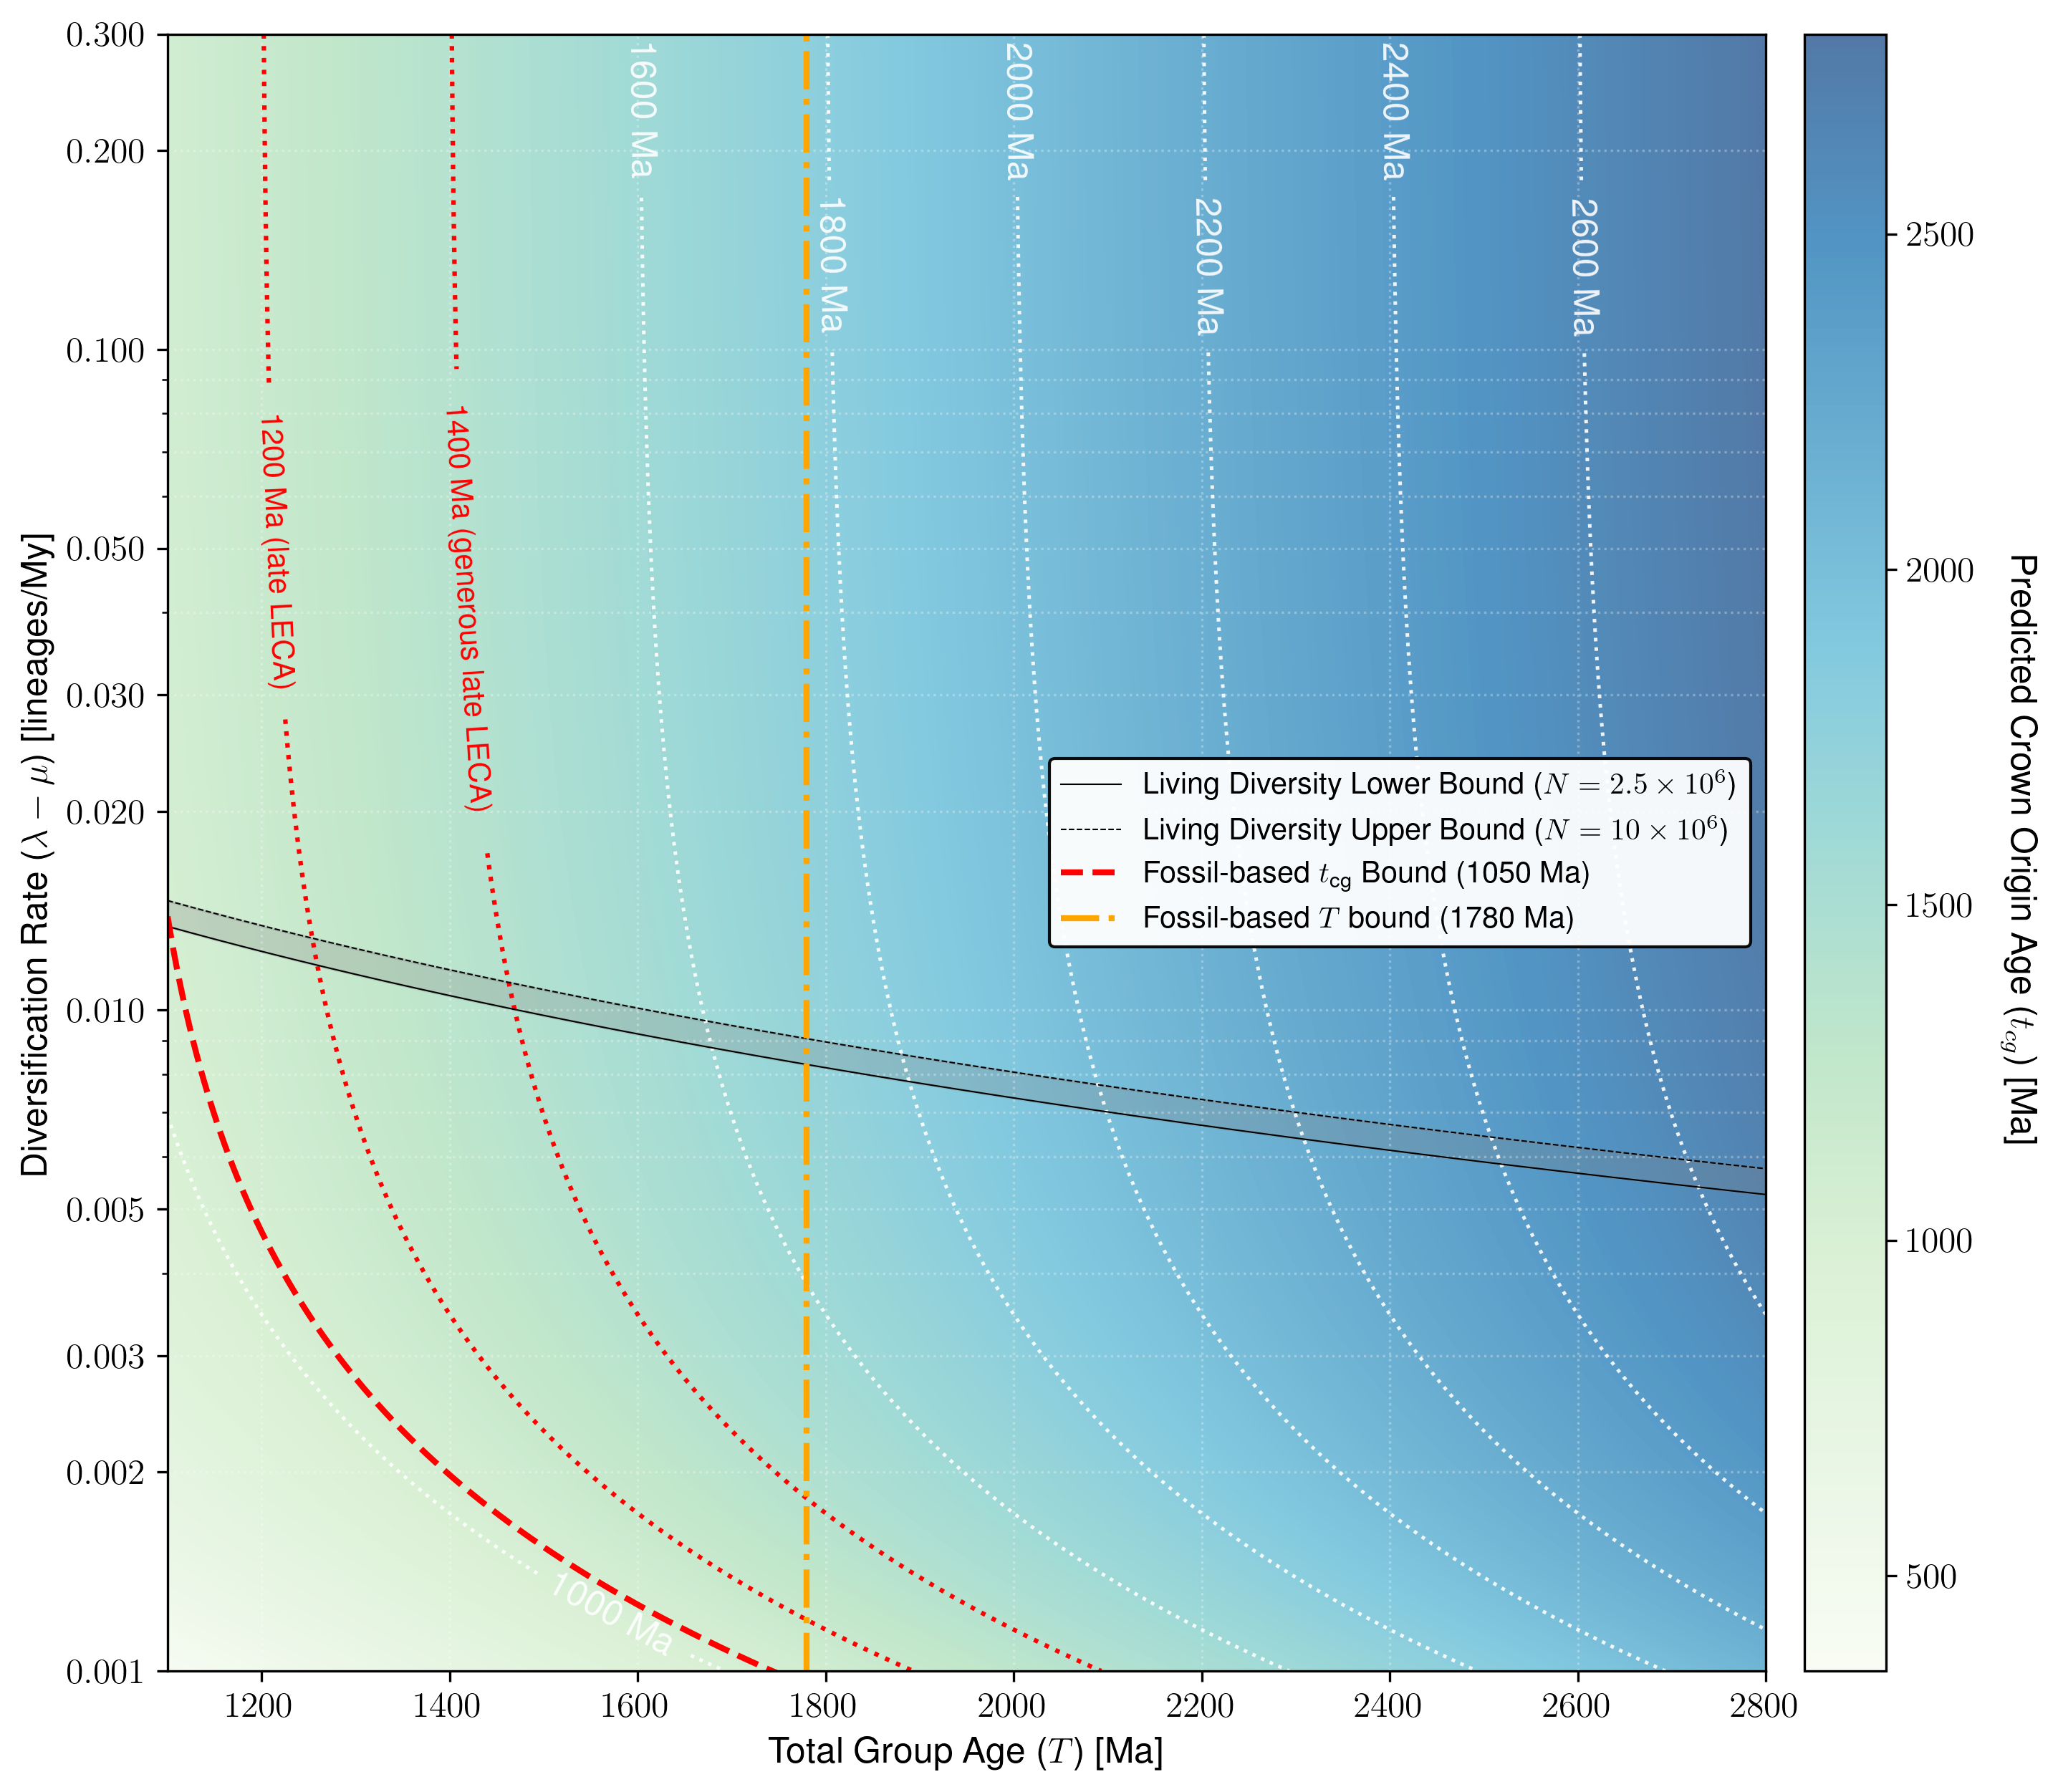

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib.ticker import ScalarFormatter, FixedLocator

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",          
    "font.sans-serif": ["Helvetica", "Arial", "Computer Modern Sans serif"],
    "text.latex.preamble": r"\usepackage{sfmath}", 
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.dpi": 300,
    "text.latex.preamble": r"\usepackage{amsmath}"
})

# --- 2. Parameters & Calculations ---
T_vals = np.linspace(1051, 2800, 2000)
div_rate_vals = np.geomspace(0.001, 0.3, 2000) 
T_grid, div_rate_grid = np.meshgrid(T_vals, div_rate_vals)

t_cg_grid = T_grid - (np.log(2) / div_rate_grid)
t_cg_grid[t_cg_grid < 0] = np.nan

N_low, N_high = 2.5e6, 10.0e6
div_rate_low = np.log(N_low) / T_vals
div_rate_high = np.log(N_high) / T_vals

fossil_leca = 1050
fossil_constraint_line = np.divide(np.log(2), (T_vals - fossil_leca), 
                                   where=(T_vals > fossil_leca))
fossil_constraint_line[T_vals <= fossil_leca] = np.nan

# --- 4. Plotting ---
fig, ax = plt.subplots(figsize=(10, 8.5))

heatmap = ax.pcolormesh(T_grid, div_rate_grid, t_cg_grid, 
                        cmap='GnBu', shading='auto', rasterized=True, alpha=0.7)
ax.set_yscale('log')

y_ticks = [0.001, 0.002, 0.003, 0.005, 0.01, 0.02, 0.03, 0.05, 0.1, 0.2, 0.3]
ax.yaxis.set_major_locator(FixedLocator(y_ticks))
formatter = ScalarFormatter()
formatter.set_scientific(False)
ax.yaxis.set_major_formatter(formatter)

cbar = fig.colorbar(heatmap, ax=ax, pad=0.02)
cbar.set_label(r'Predicted Crown Origin Age ($t_{cg}$) [Ma]', rotation=270, labelpad=20)

# --- 5. Modified Contours ---
standard_levels = [1000, 1600, 1800, 2000, 2200, 2400, 2600]
contours = ax.contour(T_grid, div_rate_grid, t_cg_grid, levels=standard_levels, 
                       colors='white', linestyles=':', linewidths=1.2, alpha=0.9)
ax.clabel(contours, inline=True, fontsize=12, fmt='%1.0f Ma')

# Red Contour 1200 - Positioned Top Left (shifted right of the 1400 line)
red_1200 = ax.contour(T_grid, div_rate_grid, t_cg_grid, levels=[1200], 
                      colors='red', linestyles=':', linewidths=1.5)
# Placement: T=1300, Rate=0.1
lbl_1200 = ax.clabel(red_1200, inline=True, fontsize=10, 
                     fmt={1200: r'{1200 Ma (late LECA)}'}, manual=[(1350, 0.05)])

# Red Contour 1400 - Positioned Top Left
red_1400 = ax.contour(T_grid, div_rate_grid, t_cg_grid, levels=[1400], 
                      colors='red', linestyles=':', linewidths=1.5)
# Placement: T=1500, Rate=0.1
lbl_1400 = ax.clabel(red_1400, inline=True, fontsize=10, 
                     fmt={1400: r'{1400 Ma (generous late LECA)}'}, manual=[(1400, 0.04)])

# Apply path effects
#plt.setp(lbl_1200 + lbl_1400, path_effects=[path_effects.withStroke(linewidth=2, foreground="white")])

# --- 6. Overlay Lines & Shading ---
ax.fill_between(T_vals, div_rate_low, div_rate_high, color='grey', alpha=0.25)
ax.plot(T_vals, div_rate_low, color='black', linewidth=0.5, linestyle='-', 
        label=r'Living Diversity Lower Bound ($N=2.5 \times 10^6$)')
ax.plot(T_vals, div_rate_high, color='black', linewidth=0.5, linestyle='--', 
        label=r'Living Diversity Upper Bound ($N=10 \times 10^6$)')
ax.plot(T_vals, fossil_constraint_line, color='red', linewidth=2, linestyle='--', 
        label=rf'Fossil-based $t_{{\text{{cg}}}}$ Bound ({fossil_leca} Ma)')
ax.axvline(1780, color='orange', linestyle='-.', linewidth=2.0, 
           label='Fossil-based $T$ bound (1780 Ma)')

# --- 7. Final Formatting ---
ax.set_xlabel('Total Group Age ($T$) [Ma]')
ax.set_ylabel(r'Diversification Rate ($\lambda - \mu$) [lineages/My]')
ax.set_ylim(0.001, 0.3)
ax.set_xlim(1100, 2800)
ax.grid(True, which='both', linestyle=':', alpha=0.3, color='white')
ax.legend(loc='center right', frameon=True, facecolor='white', framealpha=0.95, edgecolor='black')

plt.tight_layout()
#plt.savefig("plot_LECA_figure_v2.pdf")
plt.show()

/var/folders/jz/0gg19x2n28n615n9r6mnsn1w0000gp/T/ipykernel_6067/3646218595.py:32: RuntimeWarning: overflow encountered in exp
  N_grid[valid] = np.exp((T_grid[valid] * np.log(2)) / diff[valid])


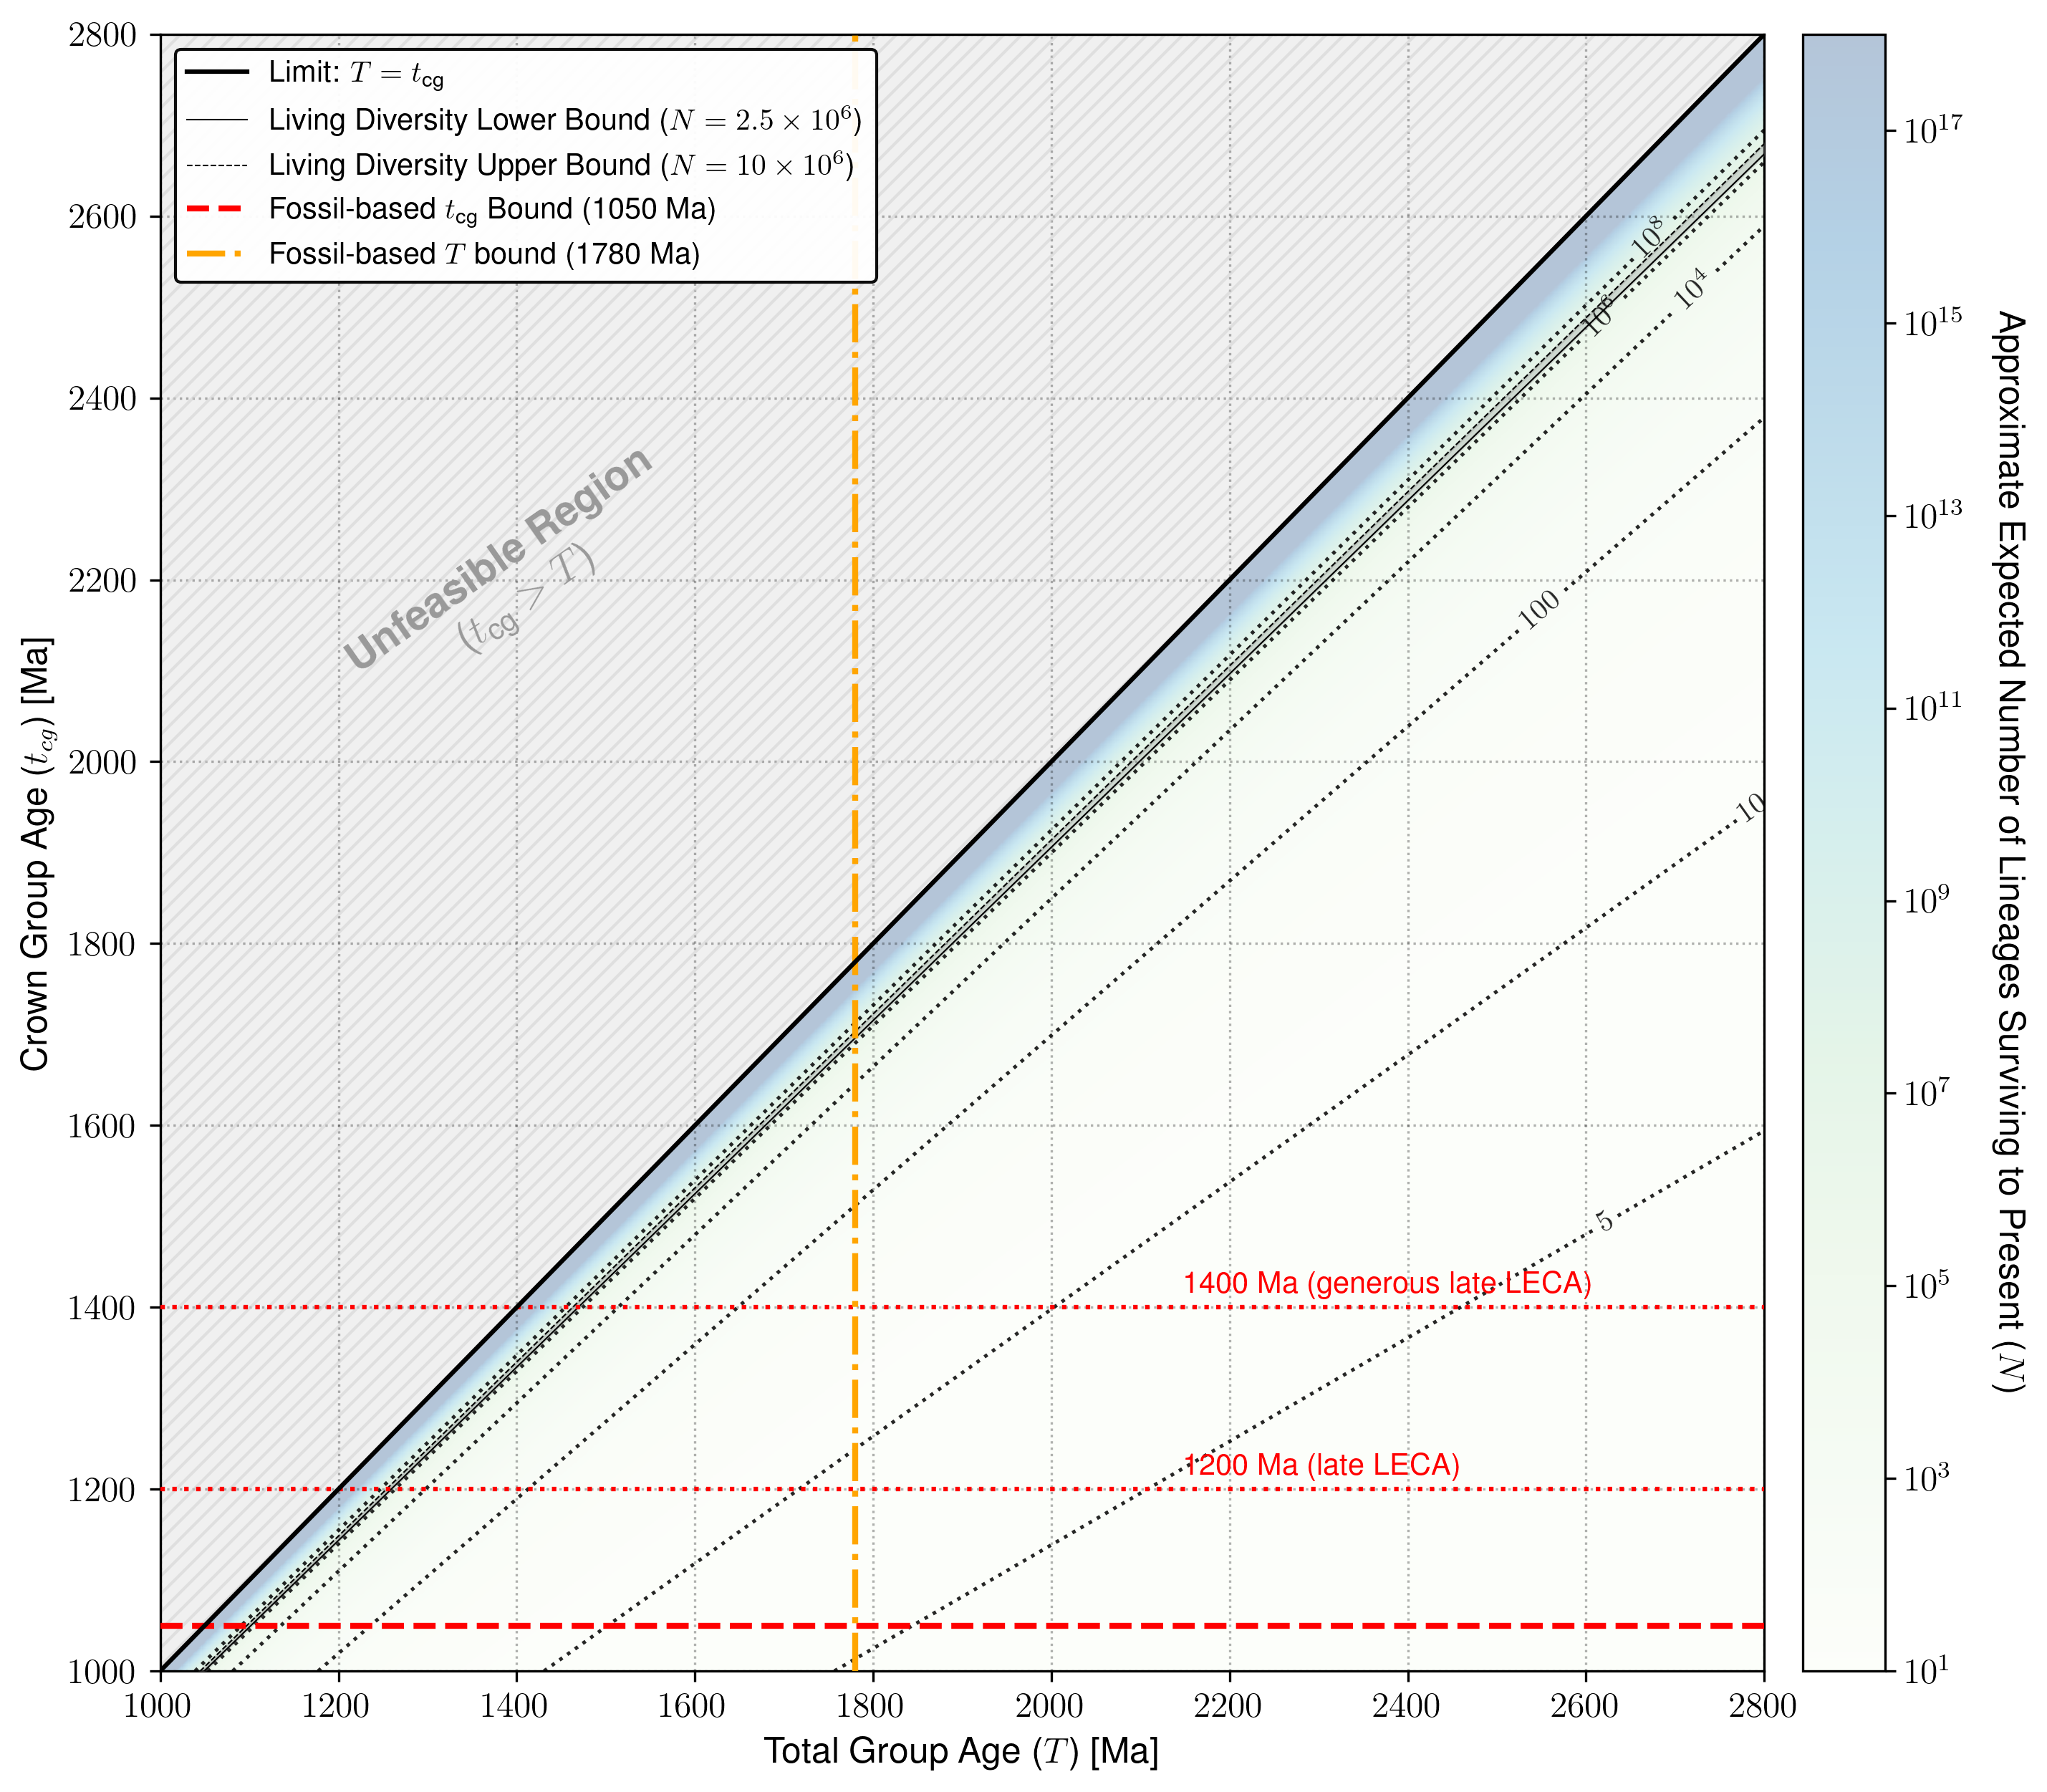

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib.colors import LogNorm

# --- 1. Scientific Styling ---
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "Computer Modern Sans serif"],
    "text.latex.preamble": r"\usepackage{sfmath}", 
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.dpi": 300,
    "text.latex.preamble": r"\usepackage{amsmath}"
})

# --- 2. Parameters ---
T_vals = np.linspace(1000, 2800, 2000)
t_cg_vals = np.linspace(1000, 2800, 2000)
T_grid, t_cg_grid = np.meshgrid(T_vals, t_cg_vals)

# --- 3. Calculations ---
diff = T_grid - t_cg_grid
N_grid = np.full_like(T_grid, np.nan, dtype=float)

valid = diff > 1e-5 
N_grid[valid] = np.exp((T_grid[valid] * np.log(2)) / diff[valid])
N_grid = np.clip(N_grid, a_min=1, a_max=1e20)

N_low, N_high = 2.5e6, 10.0e6
t_cg_low = T_vals * (1 - (np.log(2) / np.log(N_low)))
t_cg_high = T_vals * (1 - (np.log(2) / np.log(N_high)))

fossil_leca = 1050 

# --- 4. Plotting ---
fig, ax = plt.subplots(figsize=(10, 8.5))

# Heatmap set to alpha=0 (Invisible, but keeps colorbar logic valid)
heatmap = ax.pcolormesh(T_grid, t_cg_grid, N_grid, 
                        cmap='GnBu', shading='auto', rasterized=True,
                        norm=LogNorm(vmin=10, vmax=1e18), alpha=0.3)

# Unfeasible Region Styling
ax.fill_between(T_vals, T_vals, 2800, color='#f0f0f0', alpha=1.0, zorder=1.5)
ax.fill_between(T_vals, T_vals, 2800, facecolor="none", hatch='////', edgecolor='#d0d0d0', alpha=0.5, zorder=2)
ax.text(1400, 2200, r'\textbf{Unfeasible Region}' + '\n' + r'($t_{{\text{{cg}}}} > T$)', color='#999999', 
        fontsize=14, ha='center', va='center', rotation=35, zorder=3)

# Colorbar (Note: This will look empty if heatmap alpha is 0)
cbar = fig.colorbar(heatmap, ax=ax, pad=0.02)
cbar.set_label(r'Approximate Expected Number of Lineages Surviving to Present ($N$)', rotation=270, labelpad=20)

# --- 5. Contours ---
contour_levels = [5,10, 1e2, 1e4, 1e6, 1e8]
contours = ax.contour(T_grid, t_cg_grid, N_grid, levels=contour_levels, 
                       colors='black', linestyles=':', linewidths=1.2, alpha=0.85, zorder=4)

def format_exp(x):
    if x < 1e3: return f"${int(x)}$"
    return rf"$10^{{{int(np.log10(x))}}}$"
ax.clabel(contours, inline=True, fontsize=10, fmt=format_exp)

# --- 6. Overlay Lines ---
pe_white = [path_effects.withStroke(linewidth=3, foreground='white')]

# Diversity Uncertainty Shading
ax.fill_between(T_vals, t_cg_low, t_cg_high, color='grey', alpha=0.25, zorder=5)

# Boundary Line
ax.plot([1000, 2800], [1000, 2800], color='black', linestyle='-', linewidth=1.5, 
        label=r'Limit: $T = t_{{\text{{cg}}}}$', zorder=8)

# 1200 Ma: Late LECA
ax.axhline(1200, color='red', linestyle=':', linewidth=1.5, zorder=7)

# 1400 Ma: Generous Late LECA
ax.axhline(1400, color='red', linestyle=':', linewidth=1.5, zorder=7)

# Bound Lines
ax.plot(T_vals, t_cg_low, color='black', linewidth=0.5, linestyle='-', 
        label=rf'Living Diversity Lower Bound ($N=2.5 \times 10^6$)', zorder=6)

ax.plot(T_vals, t_cg_high, color='black', linewidth=0.5, linestyle='--', 
        label=rf'Living Diversity Upper Bound ($N=10 \times 10^6$)', zorder=6)

ax.axhline(fossil_leca, color='red', linewidth=2, linestyle='--', 
           label=rf'Fossil-based $t_{{\text{{cg}}}}$ Bound ({fossil_leca} Ma)', zorder=7)

ax.axvline(1780, color='orange', linestyle='-.', linewidth=2, 
           label='Fossil-based $T$ bound (1780 Ma)', zorder=7)

# --- 7. Final Formatting & LATE PLOTTED LABELS ---
ax.set_xlabel('Total Group Age ($T$) [Ma]')
ax.set_ylabel(r'Crown Group Age ($t_{cg}$) [Ma]')
ax.set_xlim(1000, 2800)
ax.set_ylim(1000, 2800)
ax.grid(True, which='both', linestyle=':', alpha=0.3, color='black', zorder=0)

# Legend
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.95, edgecolor='black').set_zorder(10)

# PLOTTING LABELS LAST TO ENSURE TOP OVERLAY
ax.text(2150, 1215, r'{1200 Ma (late LECA)}', color='red', 
        fontsize=10,  zorder=100)

ax.text(2150, 1415, r'1400 Ma (generous late LECA)', color='red', 
        fontsize=10, zorder=100)

plt.tight_layout()
#plt.savefig("Diversity_bounds_figure_2.pdf")
plt.show()